# Lecture 18 notebook: the order book

This notebook replays Lecture 18 on Bybit's BTCUSDT perpetual. Every figure and number of the lecture comes from a script in `scripts/`, next to
this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | The book at one moment: walking it, the path of an order, and what L2 shows of a queue | §1–§2 |
| 2 | The data as they look: raw lines, tables, downloading | §3 |
| 3 | Reconstructing the book: the check, the feed gaps, the clocks | §4 |
| 4 | What the book shows: spread, depth, cost, 45 days, the cascade | §5.1–§5.4 |
| 5 | The book in motion: quote fading, refill, pulls | §5.5 |
| 6 | A test of your own: an older book | §6.2 |

**Before you start.** The data live in the folder of the environment variable `BYBIT_ROOT` (default: `data/bybit` at the top of the
repository), as `raw/` (the downloads) and `parquet/` (the converted tables); §2 shows how to fill it. Two kinds of runs are offered:

* **The check (default).** Sections 1 to 5 rerun every measure of the lecture on one day, `CHECK_DAY`, compare it with the lecture's numbers
  for that day, and redraw the 45-day figures from the results shipped in `results/`. It needs the raw sample day of §1–§3 (12 March 2024) and
  the Parquet tables of `CHECK_DAY` and of 25 September 2025 (the feed gap of figure 18_04), and takes about twenty minutes, eight of them for streaming the sample day.
* **Everything.** With `REBUILD_ALL = True`, every measure is recomputed on every day in the data folder, and the figures are drawn from the
  new results. On the 45 days of the lecture (20 September – 3 November 2025, 8 GB of Parquet) this takes two to three hours.

Results go to `BYBIT_ROOT/interim/l18` (or `L18_OUT`); figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never
overwritten.

## 0. Settings

In [1]:
import gzip, json, os, subprocess, sys, time, zipfile
from pathlib import Path
import numpy as np, pandas as pd, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l18 as L
CHECK_DAY = "2025-10-01"                                                   # the day on which every measure is rerun
REBUILD_ALL = False                                                        # True: recompute everything on every day (two to three hours)

pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", L.ROOT, "| results:", L.OUT)
print("days with a book:", len(L.days()), (L.days()[0], L.days()[-1]) if L.days() else "")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to L.OUT."""
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.ROOT), "L18_OUT": str(L.OUT), "L18_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def shipped(name):
    """A result as shipped with the lecture (results/), for comparison with the rerun."""
    return json.loads((L.RESULTS / name).read_text(encoding="utf-8"))


def compare(rows):
    """rows: (measure, lecture's value, rerun's value)."""
    return pl.DataFrame(rows, schema=["measure", "lecture", "this run"], orient="row")


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: D:\trading-data\bybit | results: D:\trading-data\bybit\interim\l18_nbtest2
days with a book: 45 ('2025-09-20', '2025-11-03')
free memory: 2.2 GB of 16.9 GB


## 1. The book at one moment

The sample day is the one of §1–§3: 12 March 2024, when Bybit still recorded 500 levels. `l18_moments.py` streams its book to 12:20:30 UTC and
keeps the best 50 levels on each side (§1.1), and finds the 100-millisecond windows in which the size at the best bid fell by more than sellers
traded there (§2). Figure 18_01 is the plan of Part IV; 18_02 the book and what market buys pay by walking it; 18_03 the same moment at L1, L2
and L3 (the L3 split into orders is an illustration: L2 data do not show it).

l18_moments.py : 315 s
book at 1710246030015 best bid/ask (719500, 6.349) (719501, 0.227)
windows with fill + cancel at the best bid: 2078
{'t0': 1710244800815, 't1': 1710244800915, 'price': 72108.0, 'before': 0.565, 'traded': 0.016, 'after': 0.48, 'cancelled': 0.069, 'n_trades': 1}
{'t0': 1710244802115, 't1': 1710244802216, 'price': 72108.0, 'before': 6.759, 'traded': 0.001, 'after': 2.668, 'cancelled': 4.09, 'n_trades': 1}
{'t0': 1710244803914, 't1': 1710244804015, 'price': 72138.9, 'before': 1.204, 'traded': 0.001, 'after': 0.65, 'cancelled': 0.553, 'n_trades': 1}
{'t0': 1710244816914, 't1': 1710244817014, 'price': 72120.9, 'before': 6.464, 'traded': 0.001, 'after': 6.13, 'cancelled': 0.333, 'n_trades': 1}
{'t0': 1710244819115, 't1': 1710244819215, 'price': 72129.7, 'before': 2.77, 'traded': 0.026, 'after': 1.913, 'cancelled': 0.831, 'n_trades': 1}
{'t0': 1710244819416, 't1': 1710244819515, 'price': 72130.1, 'before': 8.546, 'traded': 0.001, 'after': 7.149, 'cancelled': 1.396, 'n_tr

l18_s1_charts.py : 9 s


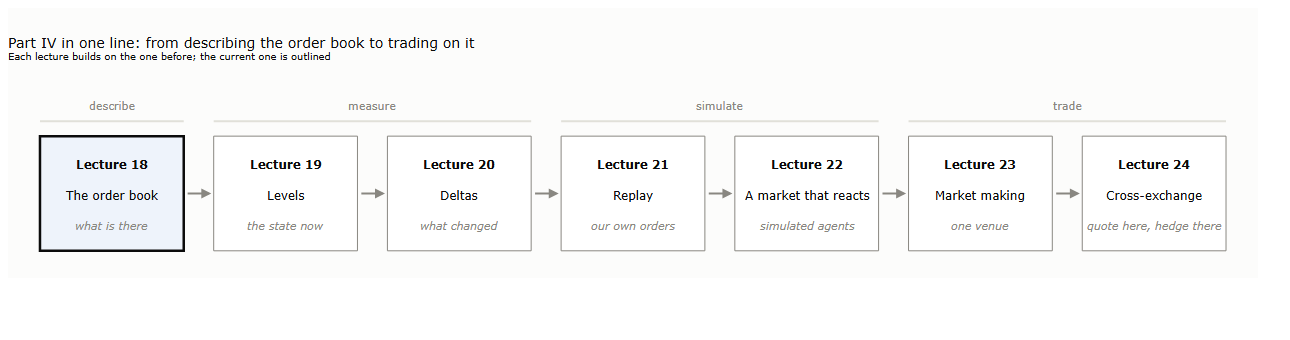

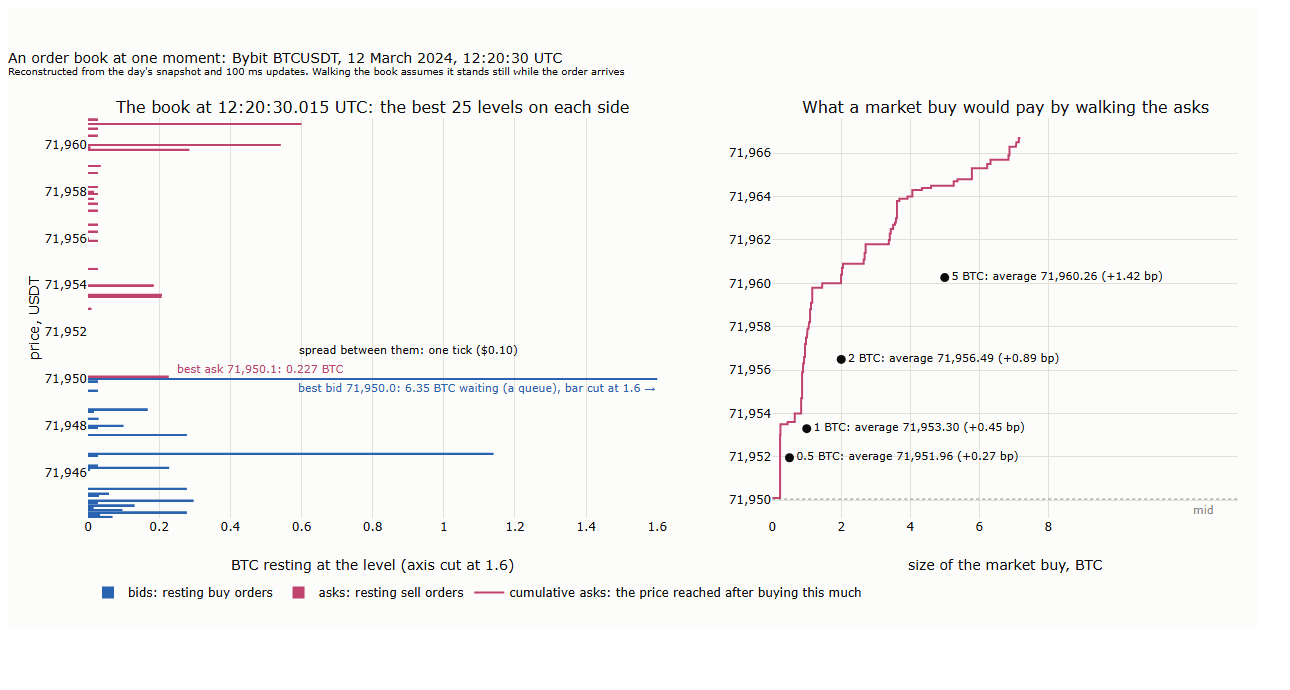

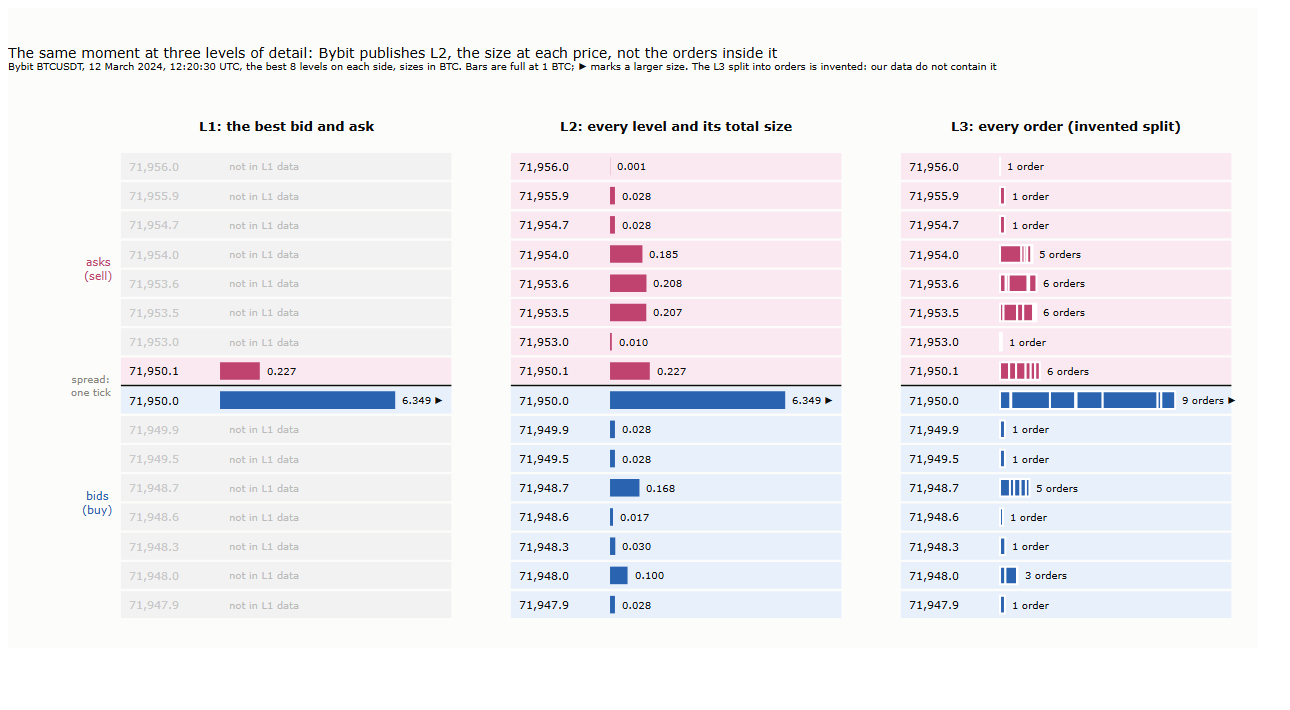

In [2]:
run("l18_moments.py", show=True)
run("l18_s1_charts.py")
pictures("18_01_part_iv", "18_02_book_moment", "18_03_l1_l2_l3")

Figure 18_02b (§1.3): the path of an order through an exchange, from the gateway to the matching engine, the market data and clearing, with what Bybit and Binance do at each step. A schematic, drawn from the venues' documentation.

l18_s13_chart.py : 3 s


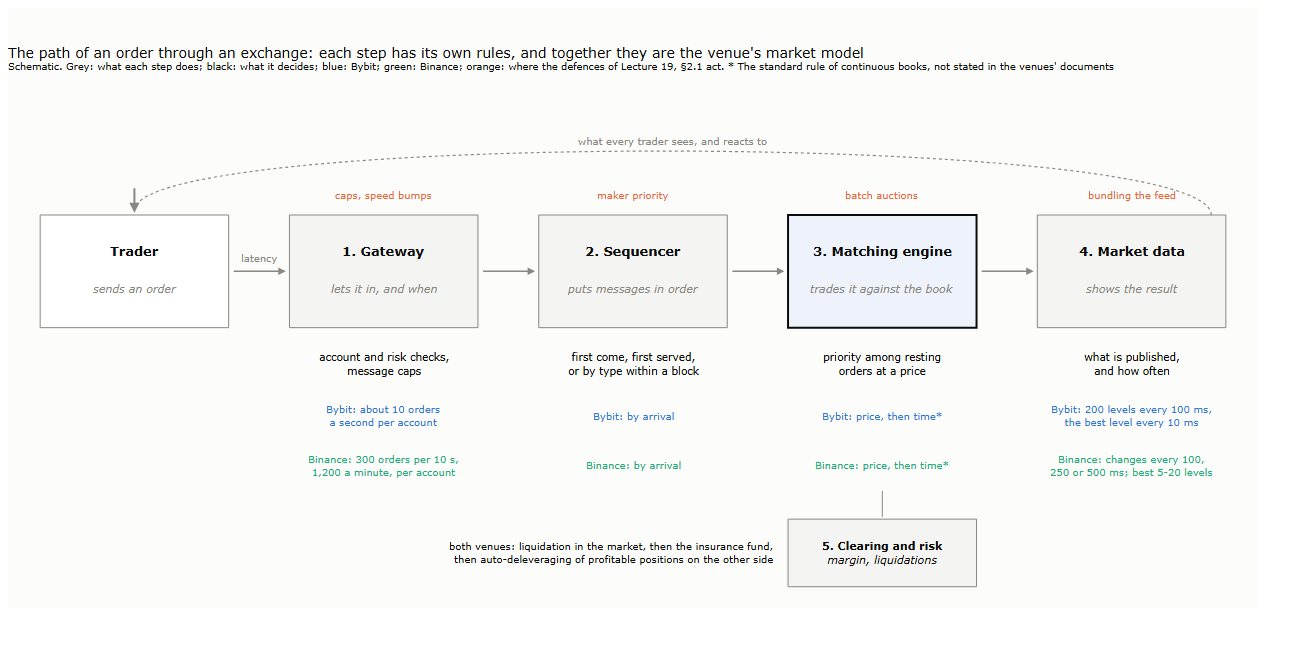

In [3]:
run("l18_s13_chart.py")
pictures("18_02b_order_path")

Walking the book of that moment (§1.2): what market buys of 0.5 to 5 BTC pay beyond the mid.

In [4]:
S = json.loads(L.result_path("l18_moments.json").read_text())["snapshot"]
asks = [(p / 10, q) for p, q in S["asks"]]; mid = (S["bids"][0][0] + S["asks"][0][0]) / 20

def walk(levels, size):
    left, cost = size, 0.0
    for p, q in levels:
        x = min(left, q); cost += x * p; left -= x
        if left <= 1e-12: return cost / size

pl.DataFrame([dict(buy_btc=s, average_price=round(walk(asks, s), 2), bp_beyond_mid=round((walk(asks, s) / mid - 1) * 1e4, 3)) for s in (0.5, 1, 2, 5)])

buy_btc,average_price,bp_beyond_mid
f64,f64,f64
0.5,71951.96,0.265
1.0,71953.3,0.451
2.0,71956.49,0.895
5.0,71960.26,1.42


The windows of §2: the size at the best bid before and after 100 milliseconds, and how much of the fall the trades explain.

In [5]:
pl.DataFrame(json.loads(L.result_path("l18_moments.json").read_text())["candidates"]).head(8)

t0,t1,price,before,traded,after,cancelled,n_trades
i64,i64,f64,f64,f64,f64,f64,i64
1710244800815,1710244800915,72108.0,0.565,0.016,0.48,0.069,1
1710244802115,1710244802216,72108.0,6.759,0.001,2.668,4.09,1
1710244803914,1710244804015,72138.9,1.204,0.001,0.65,0.553,1
1710244816914,1710244817014,72120.9,6.464,0.001,6.13,0.333,1
1710244819115,1710244819215,72129.7,2.77,0.026,1.913,0.831,1
1710244819416,1710244819515,72130.1,8.546,0.001,7.149,1.396,1
1710244822514,1710244822615,72130.1,5.526,0.001,1.865,3.66,1
1710244823715,1710244823814,72113.5,5.434,0.089,4.776,0.569,2


## 2. The data as they look

Two files a day (§3.1): the book, a zip of JSON lines, one message every 100 milliseconds; the trades, a gzipped CSV. Downloading is off by default
(`DOWNLOAD = False`); set it to `True` to fetch the days from `FIRST` to `LAST` into `BYBIT_ROOT/raw` and convert them to Parquet. Each day is about
0.2–0.4 GB of downloads; the conversion checks every day (§4.2) and deletes its raw files only if every check passes. The sample day stays raw.

In [6]:
DOWNLOAD, FIRST, LAST = False, "2025-10-01", "2025-10-01"
if DOWNLOAD:
    run("bybit_download.py", str(L.ROOT), L.SYM, FIRST, LAST, show=True)
    run("bybit_to_parquet.py", str(L.ROOT), L.SYM, show=True)

**A raw line (§3.2).** The first message of a day is a snapshot of the whole book; every later one a delta, the new size at each price that changed (`"0"`: the level is gone). The lines are long, so only their beginning is shown.

In [7]:
with zipfile.ZipFile(L.SAMPLE_BOOK) as z, z.open(z.infolist()[0]) as f:
    for i, line in enumerate(f):
        if i in (0, 1, 2): print(line[:400].decode(), "...\n")
        if i > 2: break
with gzip.open(L.SAMPLE_TRADES, "rt") as g:
    for i, line in zip(range(5), g): print(line.rstrip())

{"topic":"orderbook.500.BTCUSDT","type":"snapshot","ts":1710201601015,"data":{"s":"BTCUSDT","b":[["72156.20","8.483"],["72156.10","0.242"],["72156.00","0.070"],["72155.90","0.028"],["72155.70","0.003"],["72155.60","0.166"],["72155.50","0.003"],["72155.40","2.770"],["72155.30","0.003"],["72155.00","0.028"],["72154.70","0.028"],["72154.50","0.003"],["72154.10","1.862"],["72154.00","0.011"],["72153.9 ...

{"topic":"orderbook.500.BTCUSDT","type":"delta","ts":1710201601115,"data":{"s":"BTCUSDT","b":[["72156.20","12.021"],["72156.10","0.180"],["72155.40","0"],["72154.10","0"],["72154.00","0"],["72153.80","1.117"],["72152.10","1.862"],["72150.70","0"],["72150.40","0.077"],["72149.10","0"],["72146.30","0.010"],["72144.40","0"],["72143.60","0"],["72143.50","0"],["72142.80","0.651"],["72142.10","1.185"],[ ...

{"topic":"orderbook.500.BTCUSDT","type":"delta","ts":1710201601216,"data":{"s":"BTCUSDT","b":[["72156.20","8.002"],["72155.60","0.138"],["72154.60","2.770"],["72154.00","1.257"],["72153.80

**The same data as tables (§3.3).** The Parquet book has one row per price level changed: `ts` (sent) and `cts` (matching engine), in milliseconds; `u`, the update number; `snap`, 1 for the rows of a snapshot; `side`, +1 bid and −1 ask; `tick`, the price in $0.10; `size`, in BTC, 0 when the level is removed. The trades: time, aggressor side (+1 buyer), price, size.

In [8]:
book = pl.scan_parquet(L.BOOK / f"{CHECK_DAY}.parquet")
display(book.head(5).collect())
display(book.filter(pl.col("snap") == 0).head(8).collect())
display(pl.read_parquet(L.TRADES / f"{CHECK_DAY}.parquet").head(5))

ts,cts,u,seq,snap,side,tick,size
i64,i64,i64,i64,i8,i8,i64,f64
1759276800043,1759276799941,11085542,459034981522,1,1,1140137,6.684
1759276800043,1759276799941,11085542,459034981522,1,1,1140136,0.001
1759276800043,1759276799941,11085542,459034981522,1,1,1140135,0.018
1759276800043,1759276799941,11085542,459034981522,1,1,1140131,1.107
1759276800043,1759276799941,11085542,459034981522,1,1,1140130,3.282


ts,cts,u,seq,snap,side,tick,size
i64,i64,i64,i64,i8,i8,i64,f64
1759276800045,1759276800043,11085543,459034982121,0,1,1140137,6.454
1759276800045,1759276800043,11085543,459034982121,0,1,1140054,0.005
1759276800045,1759276800043,11085543,459034982121,0,1,1140046,0.0
1759276800045,1759276800043,11085543,459034982121,0,1,1140045,0.077
1759276800045,1759276800043,11085543,459034982121,0,1,1140044,1.728
1759276800045,1759276800043,11085543,459034982121,0,1,1140037,0.007
1759276800045,1759276800043,11085543,459034982121,0,1,1140012,0.657
1759276800045,1759276800043,11085543,459034982121,0,1,1139989,0.575


ts,side,tick,size,id,rpi
i64,i8,i64,f64,str,i8
1759276800217,1,1140138,0.002,"""0001be59-aab7-5231-92ad-bdbaf2bbde1f""",0
1759276800584,1,1140138,0.011,"""e2e403ad-9881-59cb-9086-033bddbddd7e""",0
1759276800584,1,1140138,0.001,"""eb6c5354-6b6a-504e-b3c4-cc91e987a06f""",0
1759276800584,1,1140138,0.004,"""1d37e87b-ddd1-5898-adac-11a4e32df544""",0
1759276800584,1,1140138,0.001,"""9ca091f7-711e-5ba4-8de3-25a9344da39e""",0


The same table in pandas, for readers who prefer it: a slice of one second, with prices in dollars.

In [9]:
t0 = pl.scan_parquet(L.BOOK / f"{CHECK_DAY}.parquet").select(pl.col("ts").min()).collect().item() + 12 * 3_600_000
df = (pl.scan_parquet(L.BOOK / f"{CHECK_DAY}.parquet").filter(pl.col("ts").is_between(t0, t0 + 1000)).collect().to_pandas())
df["time"] = pd.to_datetime(df["ts"], unit="ms"); df["price"] = df["tick"] / 10; df["side"] = df["side"].map({1: "bid", -1: "ask"})
df[["time", "u", "side", "price", "size"]].head(12)

,time,u,side,price,size
0,2025-10-01 12:00:00.045,11517015,bid,116730.0,5.430
1,2025-10-01 12:00:00.045,11517015,bid,116729.7,0.000
2,2025-10-01 12:00:00.045,11517015,bid,116719.0,0.024
3,2025-10-01 12:00:00.045,11517015,bid,116718.3,0.095
4,2025-10-01 12:00:00.045,11517015,bid,116718.0,0.001
5,2025-10-01 12:00:00.045,11517015,bid,116717.5,0.006
6,2025-10-01 12:00:00.045,11517015,bid,116715.6,4.309
7,2025-10-01 12:00:00.045,11517015,bid,116714.6,0.003
8,2025-10-01 12:00:00.045,11517015,bid,116714.3,1.594
9,2025-10-01 12:00:00.045,11517015,bid,116712.3,0.198


## 3. Reconstructing the book

**The check (§4.2).** The book of `CHECK_DAY` is rebuilt from its first snapshot by applying every delta, and compared, level by level, with
every snapshot that follows continuous data, including the next midnight's at the end of the file. A pause in the feed is reported as a gap.

In [10]:
run("l18_check.py", CHECK_DAY, show=True)

l18_check.py 2025-10-01: 18 s
2025-10-01 PASS {'segments_checked': 1, 'mismatched': 0, 'gaps': [], 'rows': 42668003}



**The feed gaps (§4.3).** The register written by the conversion, over the 45 days, and figure 18_04: the gap of 25 September, with the trades that went on during it.

day,start_ms,end_ms,seconds
str,i64,i64,f64
"""2025-09-25""",1758781210944,1758781222043,11.1
"""2025-10-14""",1760422462644,1760422472911,10.3
"""2025-10-23""",1761187964812,1761187974572,9.8


l18_s4_chart.py : 9 s


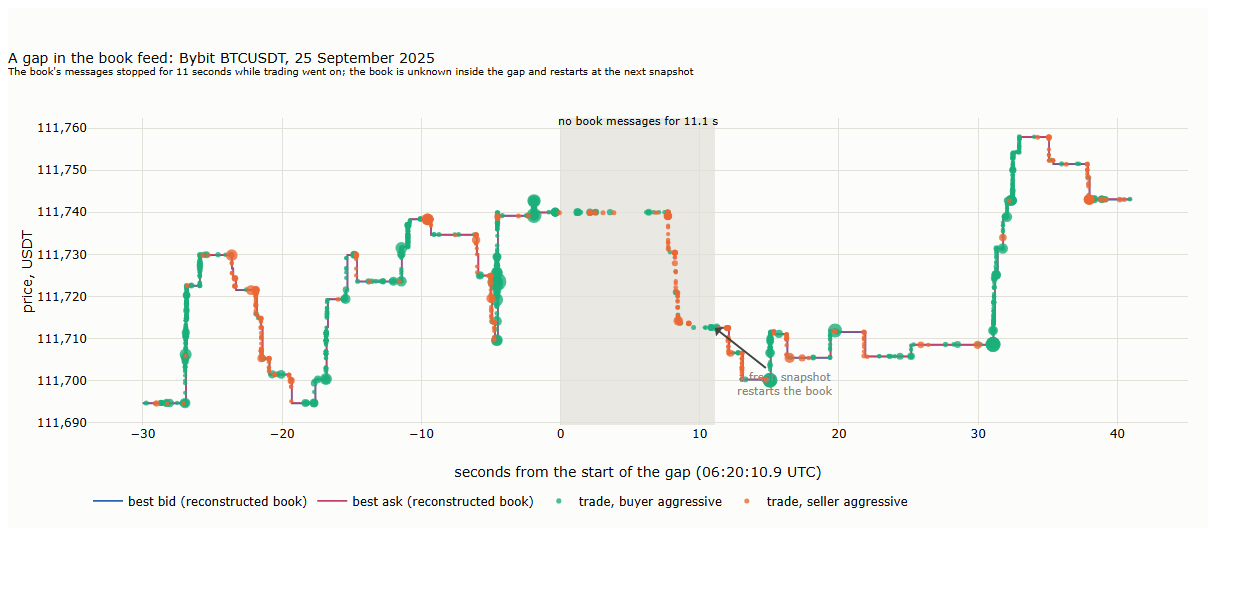

In [11]:
display(pl.read_csv(L.gaps_path()))
run("l18_s4_chart.py")
pictures("18_04_feed_gap")

**Lining up the book with the trades (§4.4).** Which clock fits, and where in the book the trades happen; the lecture's values are for 1 October 2025.

In [12]:
run("l18_align.py", CHECK_DAY); run("l18_trade_vs_book.py", CHECK_DAY)
a, a0 = json.loads((L.OUT / f"l18_align_{CHECK_DAY}.json").read_text()), shipped("l18_align_2025-10-01.json")
display(compare([(f"on a resting level, clock {k}", a0[k]["on_a_resting_level"], a[k]["on_a_resting_level"]) for k in a0]))
w, w0 = json.loads((L.OUT / f"l18_trade_vs_book_{CHECK_DAY}.json").read_text()), shipped("l18_trade_vs_book_2025-10-01.json")
compare([(f"{g}: {k}", w0[g][k], w[g][k]) for g in ("all trades", "first trade of each millisecond") for k in w0[g] if k != "trades"])

l18_align.py 2025-10-01: 113 s


l18_trade_vs_book.py 2025-10-01: 31 s


measure,lecture,this run
str,f64,f64
"""on a resting level, clock ts""",0.9041,0.9041
"""on a resting level, clock cts""",0.9059,0.9059
"""on a resting level, clock cts-100 ms""",0.3042,0.3042
"""on a resting level, clock cts+100 ms""",0.8636,0.8636


measure,lecture,this run
str,f64,f64
"""all trades: better than the best (book had moved)""",0.0316,0.0316
"""all trades: at the best""",0.3393,0.3393
"""all trades: deeper than the best (walked the book)""",0.6291,0.6291
"""first trade of each millisecond: better than the best (book had moved)""",0.0378,0.0378
"""first trade of each millisecond: at the best""",0.7191,0.7191
"""first trade of each millisecond: deeper than the best (walked the book)""",0.2432,0.2432


## 4. What the book shows

The per-second record of §5 (best prices, depth within 5 bp of the mid, imbalance, the cost of 1 and 5 BTC market orders) is built by the
viewer of §4.1 and kept in its cache. Here it is rebuilt for `CHECK_DAY` and compared with the lecture's daily values; the 45-day figures
18_05 and 18_06 are drawn from the shipped results, or from new ones if `REBUILD_ALL`.

In [13]:
run("l18_seconds.py", "--rebuild", CHECK_DAY)
sec = pl.read_parquet(L.ROOT / "viewer_cache" / L.SYM / f"{CHECK_DAY}_seconds.parquet").with_columns((pl.col("ask") - pl.col("bid")).alias("spread"))
lec = next(r for r in shipped("l18_s5_summary.json")["by_day"] if r["day"] == CHECK_DAY)
compare([("seconds wider than one tick", lec["share_wider_than_1_tick"], (sec["spread"] > 1).mean()),
         ("depth within 5 bp, bids, BTC", lec["depth_bid"], sec["depth_bid"].median()), ("depth within 5 bp, asks, BTC", lec["depth_ask"], sec["depth_ask"].median()),
         ("5 BTC market buy, bp, median second", lec["buy_5_bp"], sec["buy_5"].median()), ("5 BTC market buy, bp, worst 1%", lec["buy_5_p99_bp"], sec["buy_5"].quantile(0.99))])

l18_seconds.py --rebuild 2025-10-01: 22 s


measure,lecture,this run
str,f64,f64
"""seconds wider than one tick""",0.00147,0.00147
"""depth within 5 bp, bids, BTC""",64.324,64.324
"""depth within 5 bp, asks, BTC""",71.921,71.921
"""5 BTC market buy, bp, median second""",0.083606,0.083606
"""5 BTC market buy, bp, worst 1%""",1.140729,1.140729


l18_s5_charts.py : 5 s


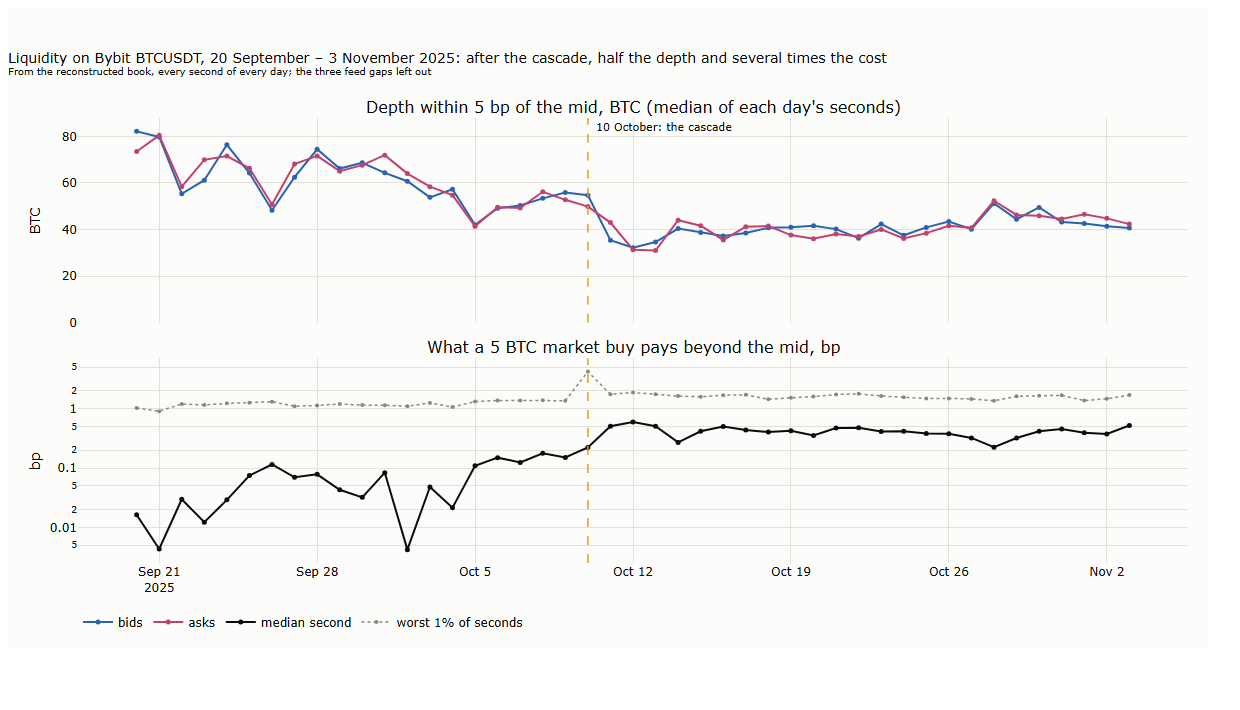

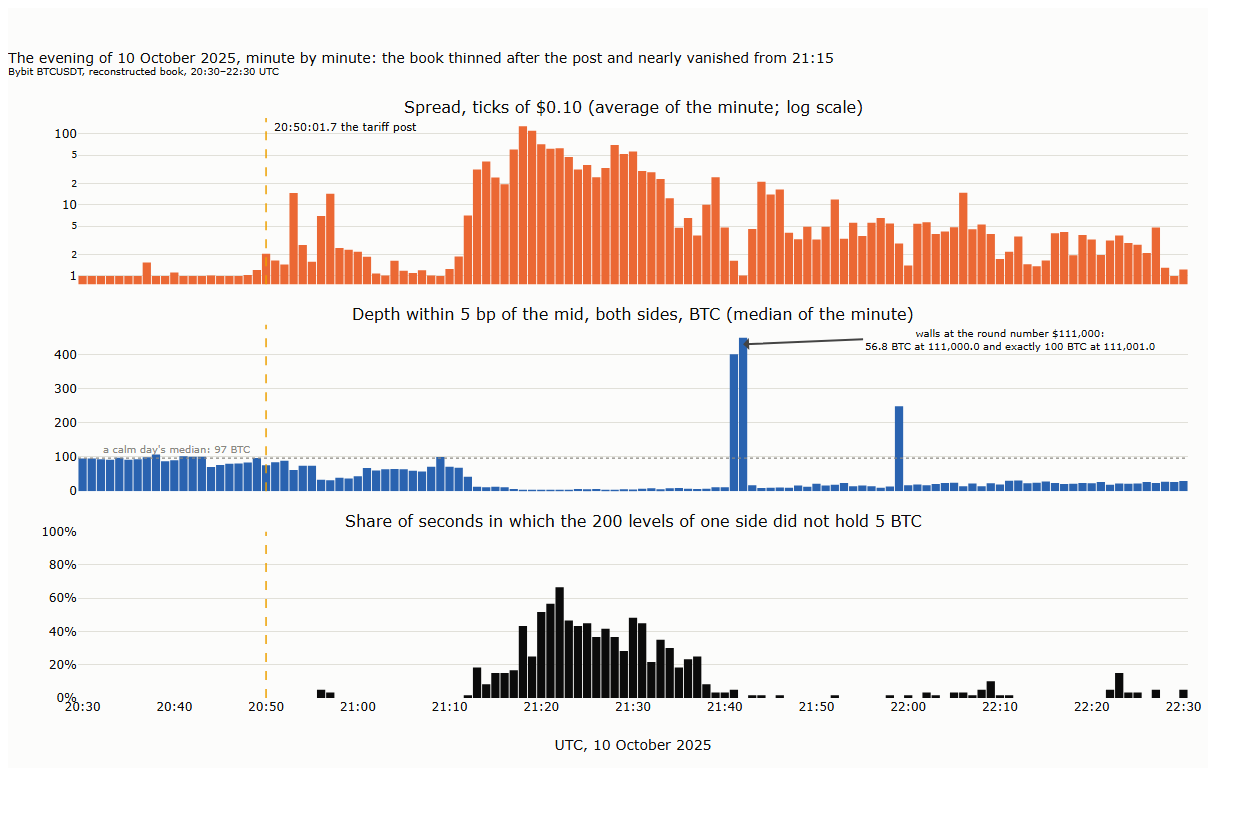

In [14]:
if REBUILD_ALL:
    run("l18_seconds.py"); run("l18_s5_summary.py")                         # about 1.5 minutes a day
run("l18_s5_charts.py")
pictures("18_05_liquidity_45_days", "18_06_cascade_book")

## 5. The book in motion

**Quote fading and refill.** `l18_sweeps.py` takes every market order of 1 BTC or more (all fills of one side in the same millisecond), walks the
book as of its last message before the order, and compares the promised price with the one paid; for orders of 2 BTC or more, it times the
refill. **Pulls.** `l18_pulls.py` counts, in every update, the levels among the best 20 of each side that shrank by more than was traded there.
Both run on `CHECK_DAY` and are compared with the lecture's values for that day.

In [15]:
run("l18_sweeps.py", CHECK_DAY, show=True); run("l18_pulls.py", CHECK_DAY)
S = pl.read_parquet(L.OUT / "sweeps" / f"{CHECK_DAY}.parquet").drop_nulls("predicted_bp")
lec = next(r for r in shipped("l18_s55_summary.json")["by_day"] if r["day"] == CHECK_DAY)
P = pl.read_parquet(L.OUT / "pulls" / f"{CHECK_DAY}.parquet"); lp = next(r for r in shipped("l18_s55_summary.json")["pulls"] if r["day"] == CHECK_DAY)
compare([("market orders of 1 BTC or more", lec["orders"], len(S)), ("did worse than promised", lec["worse"], (S["fade_bp"] > 0.05).mean()),
         ("did better", lec["better"], (S["fade_bp"] < -0.05).mean()), ("mean fade, bp", lec["fade_mean"], S["fade_bp"].mean()),
         ("refill: median seconds", lec["refill_med"], S["refill_s"].median()),
         ("updates that are pulls", lp["rate"], P["pull"].mean()), ("pulls at second 0 of the minute", lp["sec0"], P.filter(pl.col("sec") == 0)["pull"].mean())])

l18_sweeps.py 2025-10-01: 31 s
2025-10-01 30 s, orders >= 1.0 BTC: 15778, median fade 0.00 bp



l18_pulls.py 2025-10-01: 87 s


measure,lecture,this run
str,f64,f64
"""market orders of 1 BTC or more""",15681.0,15681.0
"""did worse than promised""",0.214718,0.214718
"""did better""",0.086283,0.086283
"""mean fade, bp""",0.149498,0.149498
"""refill: median seconds""",0.082,0.082
"""updates that are pulls""",0.126414,0.126414
"""pulls at second 0 of the minute""",0.182399,0.182399


The figures 18_07 and 18_08, over the 45 days.

l18_s55_charts.py : 5 s


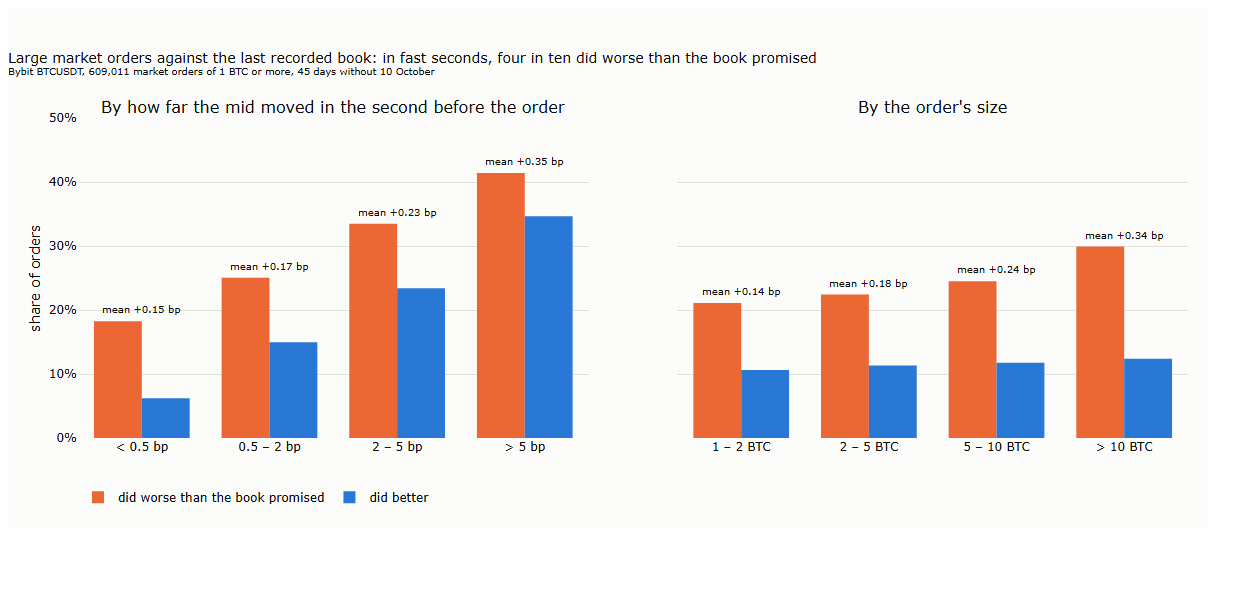

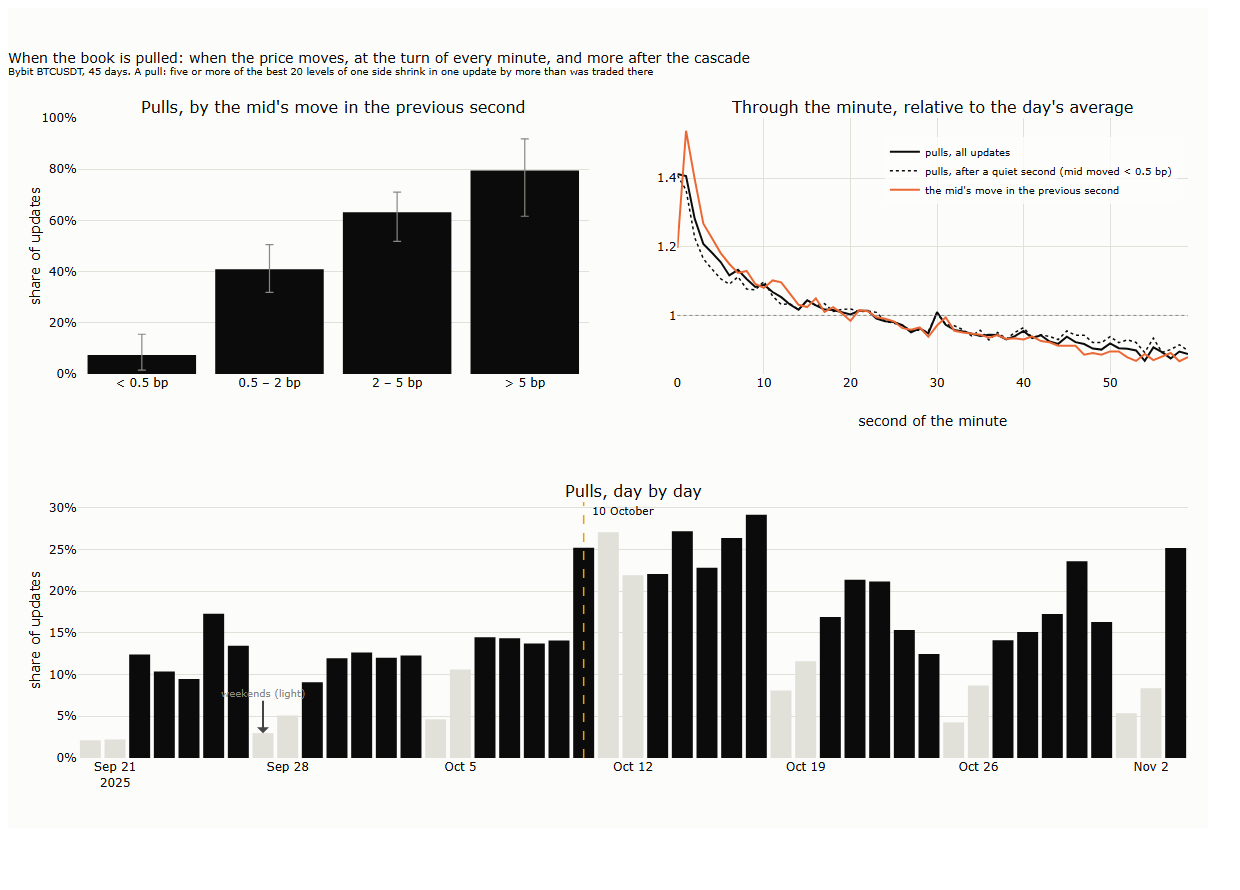

In [16]:
if REBUILD_ALL:
    run("l18_sweeps.py")                                                   # about 1 minute a day
    for d in L.days():
        if not (L.OUT / "pulls" / f"{d}.parquet").exists(): run("l18_pulls.py", d)   # about 1.5 minutes a day
    run("l18_s55_summary.py"); run("l18_s55_clock.py"); run("l18_s55_turn.py")
run("l18_s55_charts.py")
pictures("18_07_quote_fading", "18_08_pulls")

## 6. A test of your own: an older book

Exercise 4 of §6.2: how fast does quote fading grow with the age of the book? `l18_sweeps.py --lag=MS` walks the book as of its last message
`MS` milliseconds before each order, as a trader whose view is that much older would. The result for `CHECK_DAY` at four ages; change the day,
the ages, or the size of the orders.

In [17]:
rows = []
for lag in (0, 200, 500, 1000):
    if lag: run("l18_sweeps.py", f"--lag={lag}", CHECK_DAY)
    f = L.OUT / ("sweeps" if lag == 0 else f"sweeps_lag{lag}") / f"{CHECK_DAY}.parquet"
    X = pl.read_parquet(f).drop_nulls("predicted_bp")
    rows.append(dict(book_age_ms=lag, orders=len(X), did_worse=(X["fade_bp"] > 0.05).mean(), did_better=(X["fade_bp"] < -0.05).mean(), mean_fade_bp=X["fade_bp"].mean()))
pl.DataFrame(rows)

l18_sweeps.py --lag=200 2025-10-01: 32 s


l18_sweeps.py --lag=500 2025-10-01: 32 s


l18_sweeps.py --lag=1000 2025-10-01: 32 s


book_age_ms,orders,did_worse,did_better,mean_fade_bp
i64,i64,f64,f64,f64
0,15681,0.214718,0.086283,0.149498
200,15688,0.311767,0.152091,0.218807
500,15691,0.358358,0.202282,0.219116
1000,15694,0.400153,0.244106,0.259104
